In [8]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project folder
project_root = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

file_path = project_root / "data" / "raw" / "Online Retail.xlsx"

# Read both Excel sheets
sheets = pd.read_excel(file_path, sheet_name=None)

print("Sheets:", list(sheets.keys()))

# Combine both sheets into one DataFrame
df = pd.concat(sheets.values(), ignore_index=True)

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Sheets: ['Year 2009-2010', 'Year 2010-2011']

Dataset shape: (1067371, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [9]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB

Missing values:


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


Duplicate rows: 34335

Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.0,53628.0,537434.0,1350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# 1. Check duplicate rows
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

# 2. Check data types
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

# 3. Check numeric ranges
print("\nNumeric summary:")
display(df[["Quantity", "Price"]].describe())

# 4. Inspect invoice values
print("\nSample invoice values:")
display(df["Invoice"].head(10))

# 5. Count unique values
print("\nUnique invoices:", df["Invoice"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique countries:", df["Country"].nunique())
print("Unique customers:", df["Customer ID"].nunique())

Duplicate rows: 34335

Data types:


,Data Type
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
Price,float64
Customer ID,float64
Country,str



Numeric summary:


,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04



Sample invoice values:


0    489434
1    489434
2    489434
3    489434
4    489434
5    489434
6    489434
7    489434
8    489435
9    489435
Name: Invoice, dtype: object


Unique invoices: 53628
Unique products: 5305
Unique countries: 43
Unique customers: 5942


In [11]:
# Count negative quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())

# Count zero quantities
print("Zero quantities:", (df["Quantity"] == 0).sum())

# Count zero or negative prices
print("Non-positive prices:", (df["Price"] <= 0).sum())

# Inspect invoice numbers that begin with C
invoice_text = df["Invoice"].astype(str).str.strip()

print("Cancellation-style invoices:", invoice_text.str.startswith("C").sum())

# Display examples of negative quantities
display(df.loc[df["Quantity"] < 0].head(10))

# Display examples of non-positive prices
display(df.loc[df["Price"] <= 0].head(10))

Negative quantities: 22950
Zero quantities: 0
Non-positive prices: 6207
Cancellation-style invoices: 19494


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [12]:
# Create a text version of invoice numbers for analysis
invoice_text = df["Invoice"].astype(str).str.strip()

# Compare cancellation-style invoices with negative quantities
cancellation_mask = invoice_text.str.startswith("C")

print("Cancellation-style invoices:", cancellation_mask.sum())

print(
    "Cancellation-style invoices with negative quantity:",
    (cancellation_mask & (df["Quantity"] < 0)).sum()
)

print(
    "Negative quantities without a C invoice prefix:",
    ((~cancellation_mask) & (df["Quantity"] < 0)).sum()
)

# Inspect zero-price records
zero_price = df[df["Price"] == 0]

print("\nZero-price records:", len(zero_price))
print("Zero-price records with missing customer IDs:",
      zero_price["Customer ID"].isna().sum())

display(zero_price.head(10))

Cancellation-style invoices: 19494
Cancellation-style invoices with negative quantity: 19493
Negative quantities without a C invoice prefix: 3457

Zero-price records: 6202
Zero-price records with missing customer IDs: 6131


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [13]:
# Work on a separate analysis copy
analysis_df = df.copy()

# Calculate line-level revenue
analysis_df["Revenue"] = (
    analysis_df["Quantity"] * analysis_df["Price"]
)

# Identify cancellation-style invoices
analysis_df["IsCancellation"] = (
    analysis_df["Invoice"]
    .astype(str)
    .str.strip()
    .str.startswith("C")
)

# Summarize transaction groups
print("Transaction summary")

display(
    analysis_df.groupby("IsCancellation").agg(
        Rows=("Invoice", "size"),
        Negative_Quantity=("Quantity", lambda s: (s < 0).sum()),
        Zero_or_Negative_Price=("Price", lambda s: (s <= 0).sum()),
        Total_Revenue=("Revenue", "sum")
    )
)

print("\nOverall line-level revenue:", analysis_df["Revenue"].sum())

Transaction summary


,Rows,Negative_Quantity,Zero_or_Negative_Price,Total_Revenue
IsCancellation,,,,
False,1047877,3457,6207,2.081392e+07
True,19494,19493,0,-1.526668e+06



Overall line-level revenue: 19287250.568


In [14]:
# Count extra duplicate occurrences
print("Duplicate occurrences:", df.duplicated().sum())

# Count all rows that belong to a duplicate group
print(
    "Rows involved in duplicates:",
    df.duplicated(keep=False).sum()
)

# Display examples of duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

display(
    duplicate_rows
    .sort_values(["Invoice", "StockCode", "InvoiceDate"])
    .head(20)
)

Duplicate occurrences: 34335
Rows involved in duplicates: 67242


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [15]:
# Create a comparison copy with exact duplicate rows removed
df_no_duplicates = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(df_no_duplicates))
print("Rows removed:", len(df) - len(df_no_duplicates))

# Compare preliminary line-level revenue
original_revenue = (df["Quantity"] * df["Price"]).sum()

deduplicated_revenue = (
    df_no_duplicates["Quantity"] * df_no_duplicates["Price"]
).sum()

print("\nOriginal line-level revenue:", round(original_revenue, 2))
print("Revenue after deduplication:", round(deduplicated_revenue, 2))
print("Revenue difference:", round(original_revenue - deduplicated_revenue, 2))

Original rows: 1067371
Rows after removing exact duplicates: 1033036
Rows removed: 34335

Original line-level revenue: 19287250.57
Revenue after deduplication: 18855533.7
Revenue difference: 431716.87


In [16]:
# Inspect missing values after removing exact duplicates
missing_summary = pd.DataFrame({
    "Missing Count": df_no_duplicates.isna().sum(),
    "Missing Percentage": (
        df_no_duplicates.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4275,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,235151,22.76
Country,0,0.00


In [17]:
# Inspect rows with missing product descriptions
missing_descriptions = df_no_duplicates[
    df_no_duplicates["Description"].isna()
]

print("Rows with missing descriptions:", len(missing_descriptions))

print("\nUnique stock codes in these rows:",
      missing_descriptions["StockCode"].nunique())

print("\nQuantity and price summary:")
display(missing_descriptions[["Quantity", "Price"]].describe())

print("\nSample records:")
display(missing_descriptions.head(15))

Rows with missing descriptions: 4275

Unique stock codes in these rows: 2451

Quantity and price summary:


,Quantity,Price
count,4275.000000,4275.0
mean,-17.366784,0.0
std,515.938734,0.0
min,-9600.000000,0.0
25%,-28.000000,0.0
50%,-4.000000,0.0
75%,3.000000,0.0
max,9600.000000,0.0



Sample records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom
6576,489901,21098,NaN,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom
6581,489903,21166,NaN,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom


In [18]:
# Find stock codes with missing descriptions
missing_codes = df_no_duplicates.loc[
    df_no_duplicates["Description"].isna(),
    "StockCode"
].unique()

# Build a lookup of stock codes and their known descriptions
description_lookup = (
    df_no_duplicates.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else None)
)

# Check how many missing-description stock codes have known descriptions
recoverable_codes = [
    code for code in missing_codes
    if code in description_lookup.index
]

print("Unique stock codes with missing descriptions:", len(missing_codes))
print("Codes with a known description elsewhere:", len(recoverable_codes))
print("Codes with no known description elsewhere:",
      len(missing_codes) - len(recoverable_codes))

Unique stock codes with missing descriptions: 2451
Codes with a known description elsewhere: 2096
Codes with no known description elsewhere: 355


In [19]:
# Create a separate working copy
df_clean = df_no_duplicates.copy()

# Build a lookup using the most common known description for each stock code
description_lookup = (
    df_clean.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else None)
)

# Fill missing descriptions only when a known description exists
missing_before = df_clean["Description"].isna().sum()

df_clean["Description"] = df_clean["Description"].fillna(
    df_clean["StockCode"].map(description_lookup)
)

missing_after = df_clean["Description"].isna().sum()
recovered = missing_before - missing_after

print("Missing descriptions before:", missing_before)
print("Descriptions recovered:", recovered)
print("Missing descriptions remaining:", missing_after)

Missing descriptions before: 4275
Descriptions recovered: 3912
Missing descriptions remaining: 363


In [20]:
# Check missing customer IDs
missing_customers = df_clean["Customer ID"].isna().sum()
missing_customer_pct = (
    df_clean["Customer ID"].isna().mean() * 100
)

print("Missing customer IDs:", missing_customers)
print("Missing customer percentage:", round(missing_customer_pct, 2), "%")

# Separate records for customer-level analysis
customer_analysis_df = df_clean.dropna(
    subset=["Customer ID"]
).copy()

print("\nRows available for customer-level analysis:",
      len(customer_analysis_df))

print("Rows retained in the main dataset:", len(df_clean))

Missing customer IDs: 235151
Missing customer percentage: 22.76 %

Rows available for customer-level analysis: 797885
Rows retained in the main dataset: 1033036


In [21]:
# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Convert customer IDs to nullable integers
df_clean["customer_id"] = df_clean["customer_id"].astype("Int64")

# Create the customer-level dataset again
customer_analysis_df = df_clean.dropna(
    subset=["customer_id"]
).copy()

print("Updated columns:")
print(df_clean.columns.tolist())

print("\nUpdated data types:")
display(df_clean.dtypes.to_frame("Data Type"))

print("\nMain dataset shape:", df_clean.shape)
print("Customer analysis shape:", customer_analysis_df.shape)

Updated columns:
['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country']

Updated data types:


,Data Type
invoice,object
stockcode,object
description,object
quantity,int64
invoicedate,datetime64[us]
price,float64
customer_id,Int64
country,str



Main dataset shape: (1033036, 8)
Customer analysis shape: (797885, 8)


In [22]:
# Calculate line-level revenue
df_clean["revenue"] = df_clean["quantity"] * df_clean["price"]

# Check the cleaned dataset
print("Dataset shape:", df_clean.shape)
print("Missing descriptions:", df_clean["description"].isna().sum())
print("Missing customer IDs:", df_clean["customer_id"].isna().sum())
print("Exact duplicate rows:", df_clean.duplicated().sum())

# Revenue summary
print("\nRevenue summary:")
display(df_clean["revenue"].describe())

print("\nTotal net line-level revenue:",
      round(df_clean["revenue"].sum(), 2))

print("Positive revenue:",
      round(df_clean.loc[df_clean["revenue"] > 0, "revenue"].sum(), 2))

print("Negative revenue:",
      round(df_clean.loc[df_clean["revenue"] < 0, "revenue"].sum(), 2))

Dataset shape: (1033036, 9)
Missing descriptions: 363
Missing customer IDs: 235151
Exact duplicate rows: 0

Revenue summary:


count    1.033036e+06
mean     1.825254e+01
std      2.956873e+02
min     -1.684696e+05
25%      3.750000e+00
50%      9.920000e+00
75%      1.770000e+01
max      1.684696e+05
Name: revenue, dtype: float64


Total net line-level revenue: 18855533.7
Positive revenue: 20476634.02
Negative revenue: -1621100.32


In [23]:
# Create a monthly sales summary
monthly_sales = (
    df_clean
    .assign(month=df_clean["invoicedate"].dt.to_period("M"))
    .groupby("month")
    .agg(
        total_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        invoice_count=("invoice", "nunique")
    )
    .reset_index()
)

# Convert month to a timestamp for plotting
monthly_sales["month"] = monthly_sales["month"].dt.to_timestamp()

print("Monthly sales summary:")
display(monthly_sales.head(12))

Monthly sales summary:


,month,total_revenue,total_quantity,invoice_count
0,2009-12-01,796648.500,418570,2330
1,2010-01-01,622479.502,374510,1633
2,2010-02-01,531265.366,367501,1969
3,2010-03-01,763247.241,488012,2367
4,2010-04-01,587926.692,350478,1892
5,2010-05-01,613270.720,362771,2418
6,2010-06-01,677073.870,386447,2216
7,2010-07-01,573333.690,301176,2017
8,2010-08-01,654774.390,450775,1877
9,2010-09-01,851105.961,476808,2375


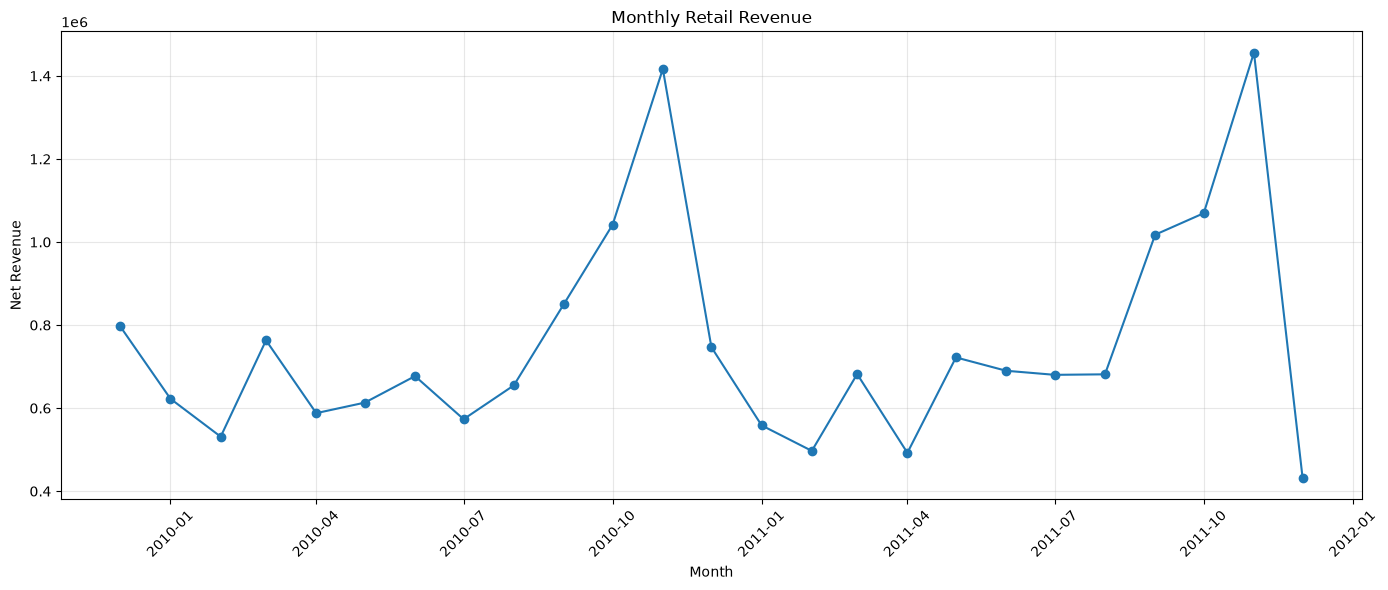

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["month"],
    monthly_sales["total_revenue"],
    marker="o"
)

plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Top 10 products by net line-level revenue
top_products = (
    df_clean.dropna(subset=["description"])
    .groupby("description")
    .agg(
        total_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        invoice_count=("invoice", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
    .head(10)
    .reset_index()
)

display(top_products)

,description,total_revenue,total_quantity,invoice_count
0,REGENCY CAKESTAND 3 TIER,314045.02,25015,4262
1,DOTCOM POSTAGE,309844.10,2917,1425
2,WHITE HANGING HEART T-LIGHT HOLDER,251603.12,91026,5594
3,PARTY BUNTING,147079.73,27963,2700
4,JUMBO BAG RED RETROSPOT,145946.05,76514,3344
5,ASSORTED COLOUR BIRD ORNAMENT,128550.42,79579,2827
6,PAPER CHAIN KIT 50'S CHRISTMAS,116298.59,34434,2036
7,POSTAGE,110430.41,10011,2084
8,CHILLI LIGHTS,79905.13,15652,1172
9,ROTATING SILVER ANGELS T-LIGHT HLDR,70969.95,22121,766


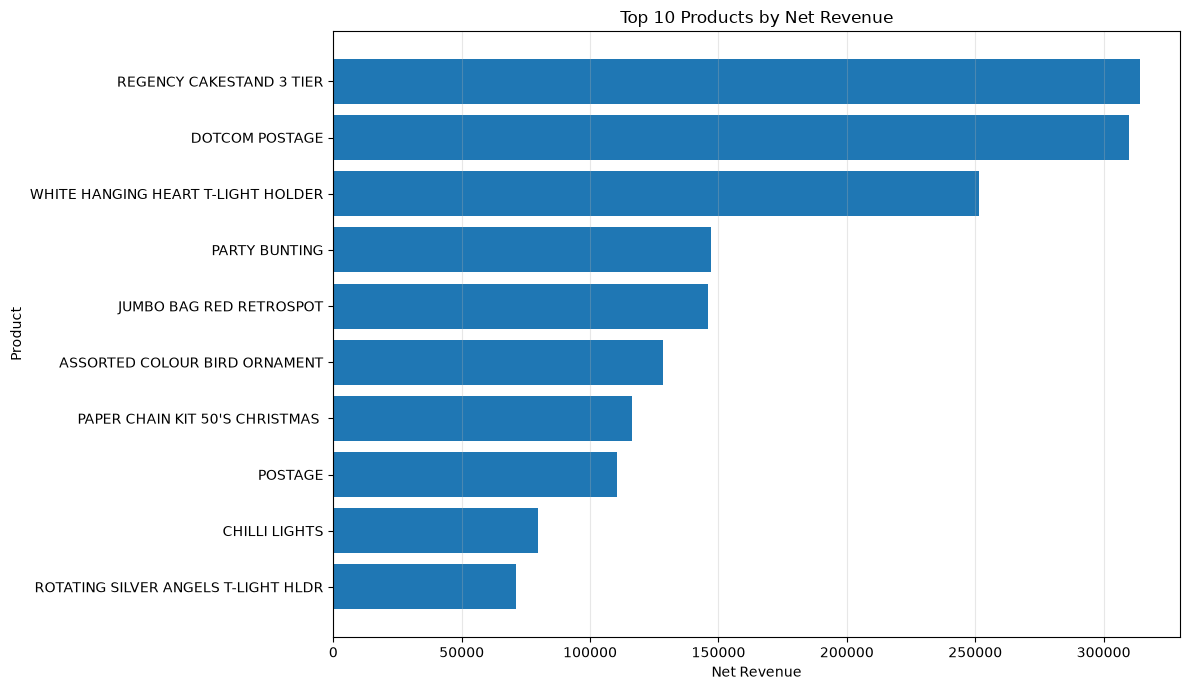

In [26]:
import matplotlib.pyplot as plt

# Sort for a horizontal bar chart
plot_data = top_products.sort_values(
    "total_revenue",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["description"],
    plot_data["total_revenue"]
)

plt.title("Top 10 Products by Net Revenue")
plt.xlabel("Net Revenue")
plt.ylabel("Product")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Country-level sales analysis
country_sales = (
    df_clean
    .groupby("country")
    .agg(
        total_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        invoice_count=("invoice", "nunique"),
        unique_customers=("customer_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)

print("Top 10 countries by net revenue:")
display(country_sales.head(10))

Top 10 countries by net revenue:


,country,total_revenue,total_quantity,invoice_count,unique_customers
0,United Kingdom,1.598606e+07,8513706,49108,5410
1,EIRE,6.099538e+05,327431,806,5
2,Netherlands,5.483307e+05,381853,250,23
3,Germany,4.119592e+05,221816,1095,107
4,France,3.217334e+05,181572,746,95
5,Australia,1.664444e+05,103375,117,15
6,Switzerland,9.940306e+04,52256,123,22
7,Spain,9.101344e+04,44667,188,41
8,Sweden,8.777552e+04,87858,129,19
9,Denmark,6.445959e+04,234764,53,12


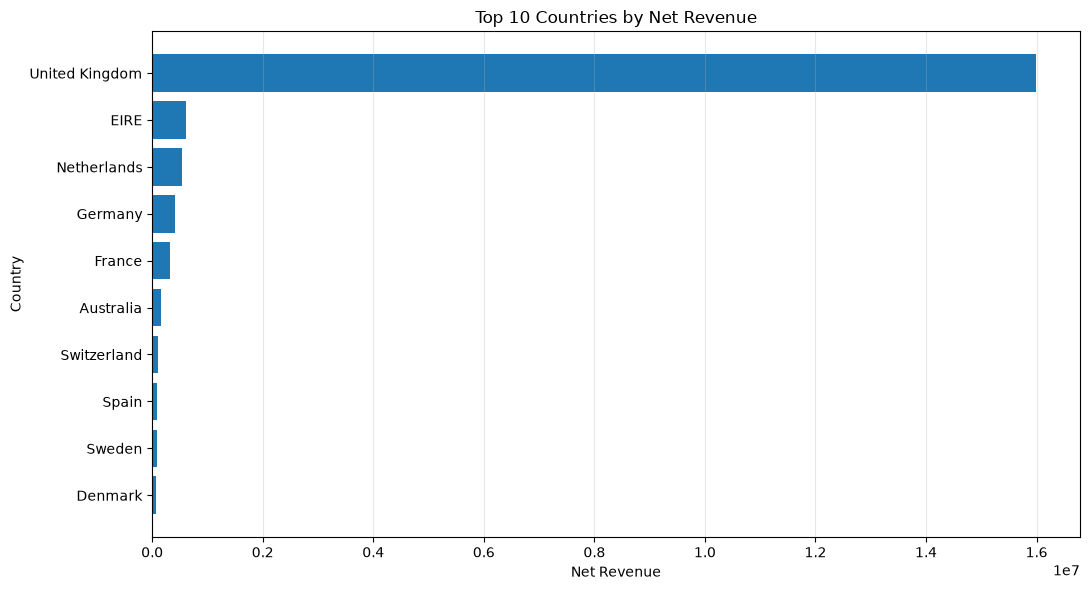

In [28]:
import matplotlib.pyplot as plt

top_countries = country_sales.head(10).sort_values(
    "total_revenue",
    ascending=True
)

plt.figure(figsize=(11, 6))
plt.barh(
    top_countries["country"],
    top_countries["total_revenue"]
)

plt.title("Top 10 Countries by Net Revenue")
plt.xlabel("Net Revenue")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Customer-level purchasing analysis
customer_sales = (
    customer_analysis_df
    .assign(
        revenue=lambda data: data["quantity"] * data["price"]
    )
    .groupby("customer_id")
    .agg(
        total_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        invoice_count=("invoice", "nunique"),
        first_purchase=("invoicedate", "min"),
        last_purchase=("invoicedate", "max")
    )
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)

print("Customer records:", len(customer_sales))
print("\nTop 10 customers by net revenue:")
display(customer_sales.head(10))

Customer records: 5942

Top 10 customers by net revenue:


,customer_id,total_revenue,total_quantity,invoice_count,first_purchase,last_purchase
0,18102,570380.61,180415,153,2009-12-01 09:24:00,2011-12-09 11:50:00
1,14646,523342.07,365220,164,2009-12-02 16:52:00,2011-12-08 12:12:00
2,14156,296063.44,162245,202,2009-12-01 12:30:00,2011-11-30 10:54:00
3,14911,265757.91,141750,510,2009-12-01 11:41:00,2011-12-08 15:54:00
4,17450,231390.55,80838,61,2010-09-27 16:59:00,2011-12-01 13:29:00
5,13694,190020.84,184534,164,2009-12-04 15:26:00,2011-12-06 09:32:00
6,17511,168491.62,115449,85,2009-12-02 10:52:00,2011-12-07 10:12:00
7,12415,143269.29,91315,33,2010-06-30 08:30:00,2011-11-15 14:22:00
8,16684,141502.25,101095,65,2009-12-07 12:56:00,2011-12-05 14:06:00
9,15061,124961.98,73554,138,2009-12-01 12:18:00,2011-12-06 12:06:00


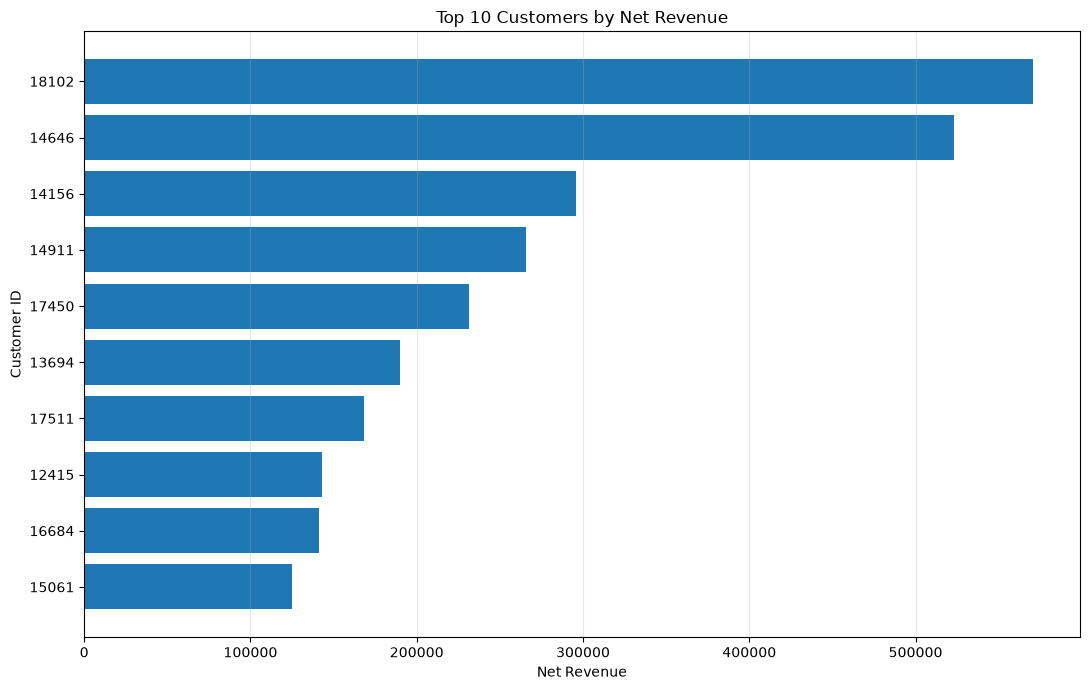

In [30]:
import matplotlib.pyplot as plt

top_customers = customer_sales.head(10).sort_values(
    "total_revenue",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_customers["customer_id"].astype(str),
    top_customers["total_revenue"]
)

plt.title("Top 10 Customers by Net Revenue")
plt.xlabel("Net Revenue")
plt.ylabel("Customer ID")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# Transaction quality analysis

print("Total rows:", len(df_clean))

print(
    "Negative quantity rows:",
    (df_clean["quantity"] < 0).sum()
)

print(
    "Zero quantity rows:",
    (df_clean["quantity"] == 0).sum()
)

print(
    "Zero or negative price rows:",
    (df_clean["price"] <= 0).sum()
)

print(
    "Cancellation-style invoice rows:",
    df_clean["invoice"].astype(str).str.startswith("C").sum()
)

print(
    "Negative revenue rows:",
    (df_clean["revenue"] < 0).sum()
)

print(
    "Positive revenue rows:",
    (df_clean["revenue"] > 0).sum()
)

print("\nLargest positive revenue transactions:")
display(
    df_clean.nlargest(
        10, "revenue"
    )[["invoice", "description", "quantity", "price", "revenue", "country"]]
)

print("\nLargest negative revenue transactions:")
display(
    df_clean.nsmallest(
        10, "revenue"
    )[["invoice", "description", "quantity", "price", "revenue", "country"]]
)

Total rows: 1033036
Negative quantity rows: 22496
Zero quantity rows: 0
Zero or negative price rows: 6019
Cancellation-style invoice rows: 19104
Negative revenue rows: 19108
Positive revenue rows: 1007914

Largest positive revenue transactions:


,invoice,description,quantity,price,revenue,country
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
748132,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
241827,512771,Manual,1,25111.09,25111.09,United Kingdom
432176,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,United Kingdom
517955,537632,AMAZON FEE,1,13541.33,13541.33,United Kingdom
825443,A563185,Adjust bad debt,1,11062.06,11062.06,United Kingdom
135013,502263,Manual,1,10953.50,10953.50,United Kingdom
135015,502265,Manual,1,10953.50,10953.50,United Kingdom
342147,522796,Manual,1,10468.80,10468.80,United Kingdom



Largest negative revenue transactions:


,invoice,description,quantity,price,revenue,country
1065883,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.60,United Kingdom
587085,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.60,United Kingdom
179403,A506401,Adjust bad debt,1,-53594.36,-53594.36,United Kingdom
276274,A516228,Adjust bad debt,1,-44031.79,-44031.79,United Kingdom
748142,C556445,Manual,-1,38970.00,-38970.00,United Kingdom
403472,A528059,Adjust bad debt,1,-38925.87,-38925.87,United Kingdom
241824,C512770,Manual,-1,25111.09,-25111.09,United Kingdom
320581,C520667,Bank Charges,-1,18910.69,-18910.69,United Kingdom
1050063,C580605,AMAZON FEE,-1,17836.46,-17836.46,United Kingdom
569163,C540117,AMAZON FEE,-1,16888.02,-16888.02,United Kingdom


In [32]:
# Inspect unusually large quantities
print("Transactions with quantity above 10,000:")
display(
    df_clean.loc[
        df_clean["quantity"] > 10_000,
        [
            "invoice", "stockcode", "description",
            "quantity", "price", "revenue", "country"
        ]
    ].sort_values("quantity", ascending=False).head(20)
)

# Inspect unusually high unit prices
print("\nTransactions with unit price above 1,000:")
display(
    df_clean.loc[
        df_clean["price"] > 1_000,
        [
            "invoice", "stockcode", "description",
            "quantity", "price", "revenue", "country"
        ]
    ].sort_values("price", ascending=False).head(20)
)

# Inspect manual adjustments and fees
print("\nManual, fee, and adjustment entries:")
display(
    df_clean.loc[
        df_clean["description"].str.contains(
            r"manual|fee|bad debt|postage",
            case=False,
            na=False
        ),
        [
            "invoice", "description", "quantity",
            "price", "revenue", "country"
        ]
    ].head(20)
)

Transactions with quantity above 10,000:


,invoice,stockcode,description,quantity,price,revenue,country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4,Denmark
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,0.0,United Kingdom
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0,Denmark
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,0.00,0.0,United Kingdom



Transactions with unit price above 1,000:


,invoice,stockcode,description,quantity,price,revenue,country
748142,C556445,M,Manual,-1,38970.00,-38970.00,United Kingdom
241827,512771,M,Manual,1,25111.09,25111.09,United Kingdom
241824,C512770,M,Manual,-1,25111.09,-25111.09,United Kingdom
320581,C520667,BANK CHARGES,Bank Charges,-1,18910.69,-18910.69,United Kingdom
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,-17836.46,United Kingdom
569163,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,-16888.02,United Kingdom
569164,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,-16453.71,United Kingdom
519294,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33,United Kingdom
517955,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,United Kingdom
517953,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33,United Kingdom



Manual, fee, and adjustment entries:


,invoice,description,quantity,price,revenue,country
40,489437,RETRO COFFEE MUGS ASSORTED,12,1.25,15.00,United Kingdom
89,489439,POSTAGE,3,18.00,54.00,France
126,489444,POSTAGE,1,141.00,141.00,USA
173,489447,POSTAGE,1,130.00,130.00,Belgium
306,489488,COFFEE MUG CAT + BIRD DESIGN,2,2.55,5.10,United Kingdom
307,489488,COFFEE MUG DOG + BALL DESIGN,3,2.55,7.65,United Kingdom
349,489514,POTTING SHED COFFEE MUG,2,1.25,2.50,United Kingdom
487,489522,POTTING SHED COFFEE MUG,1,1.25,1.25,United Kingdom
499,489522,COFFEE MUG DOG + BALL DESIGN,3,2.55,7.65,United Kingdom
500,489522,COFFEE MUG CAT + BIRD DESIGN,3,2.55,7.65,United Kingdom


In [33]:
# Create a separate dataset for preliminary merchandise sales analysis
is_cancellation = df_clean["invoice"].astype(str).str.startswith("C")

is_merchandise = ~df_clean["description"].str.contains(
    r"postage|manual|fee|bad debt|adjustment",
    case=False,
    na=False
)

sales_df = df_clean.loc[
    (~is_cancellation)
    & (df_clean["quantity"] > 0)
    & (df_clean["price"] > 0)
    & is_merchandise
].copy()

print("Original cleaned rows:", len(df_clean))
print("Rows retained for merchandise analysis:", len(sales_df))
print("Rows excluded by provisional rules:", len(df_clean) - len(sales_df))

print("\nMerchandise revenue:", round(sales_df["revenue"].sum(), 2))
print("Unique invoices:", sales_df["invoice"].nunique())
print("Unique products:", sales_df["stockcode"].nunique())
print("Countries:", sales_df["country"].nunique())

Original cleaned rows: 1033036
Rows retained for merchandise analysis: 997403
Rows excluded by provisional rules: 35633

Merchandise revenue: 19499175.72
Unique invoices: 39553
Unique products: 4878
Countries: 43


In [34]:
# Monthly merchandise-sales summary
monthly_merchandise_sales = (
    sales_df
    .assign(month=sales_df["invoicedate"].dt.to_period("M"))
    .groupby("month")
    .agg(
        merchandise_revenue=("revenue", "sum"),
        quantity_sold=("quantity", "sum"),
        invoice_count=("invoice", "nunique")
    )
    .reset_index()
)

monthly_merchandise_sales["month"] = (
    monthly_merchandise_sales["month"].dt.to_timestamp()
)

display(monthly_merchandise_sales.head(12))

,month,merchandise_revenue,quantity_sold,invoice_count
0,2009-12-01,792124.150,422717,1667
1,2010-01-01,596126.462,386839,1053
2,2010-02-01,529961.796,379159,1189
3,2010-03-01,756877.831,523068,1647
4,2010-04-01,641713.352,364037,1441
5,2010-05-01,640524.630,394126,1487
6,2010-06-01,691593.890,403739,1614
7,2010-07-01,627771.920,334625,1512
8,2010-08-01,672088.000,470768,1404
9,2010-09-01,865999.121,581827,1791


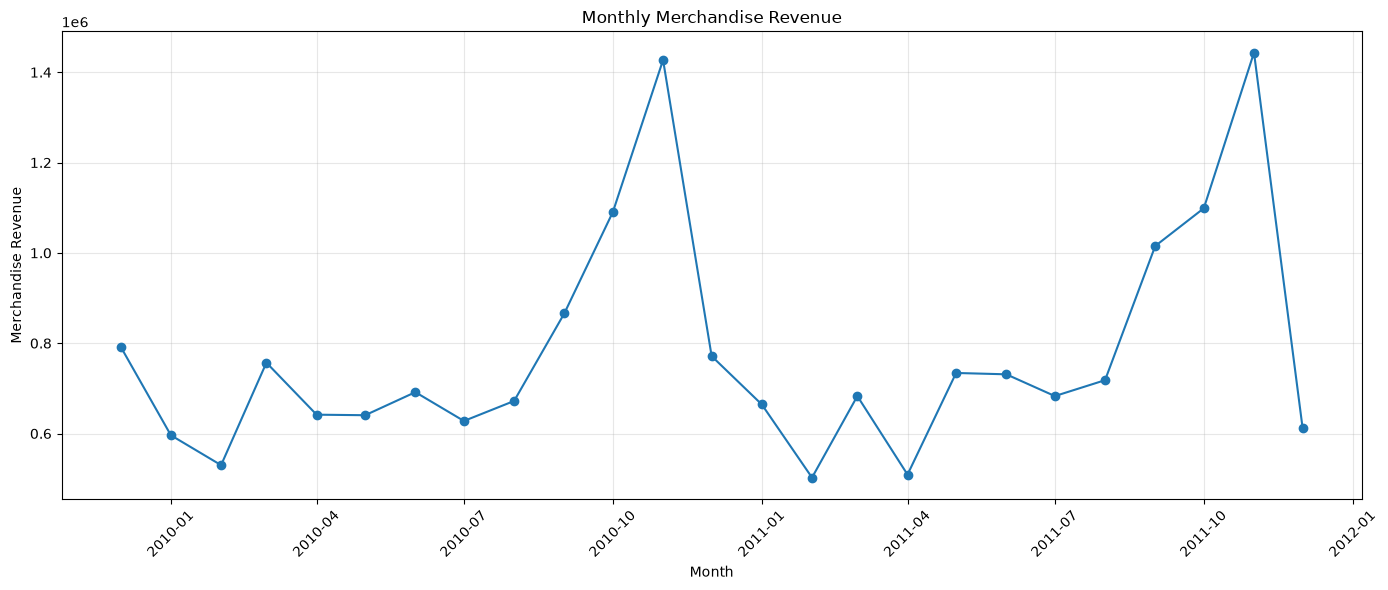

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_merchandise_sales["month"],
    monthly_merchandise_sales["merchandise_revenue"],
    marker="o"
)

plt.title("Monthly Merchandise Revenue")
plt.xlabel("Month")
plt.ylabel("Merchandise Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
# Country-level merchandise analysis
country_merchandise_sales = (
    sales_df
    .groupby("country")
    .agg(
        merchandise_revenue=("revenue", "sum"),
        quantity_sold=("quantity", "sum"),
        invoice_count=("invoice", "nunique"),
        unique_customers=("customer_id", "nunique")
    )
    .sort_values(
        "merchandise_revenue",
        ascending=False
    )
    .reset_index()
)

print("Top 10 countries by merchandise revenue:")
display(country_merchandise_sales.head(10))

Top 10 countries by merchandise revenue:


,country,merchandise_revenue,quantity_sold,invoice_count,unique_customers
0,United Kingdom,1.667121e+07,9125355,36215,5334
1,EIRE,6.272870e+05,333784,586,3
2,Netherlands,5.477054e+05,382990,216,22
3,Germany,3.789253e+05,221277,752,107
4,France,3.083181e+05,269294,601,94
5,Australia,1.654533e+05,103084,89,15
6,Spain,9.745404e+04,49805,144,38
7,Switzerland,9.358803e+04,52420,85,22
8,Sweden,8.488544e+04,88089,99,19
9,Denmark,6.732909e+04,237358,42,12


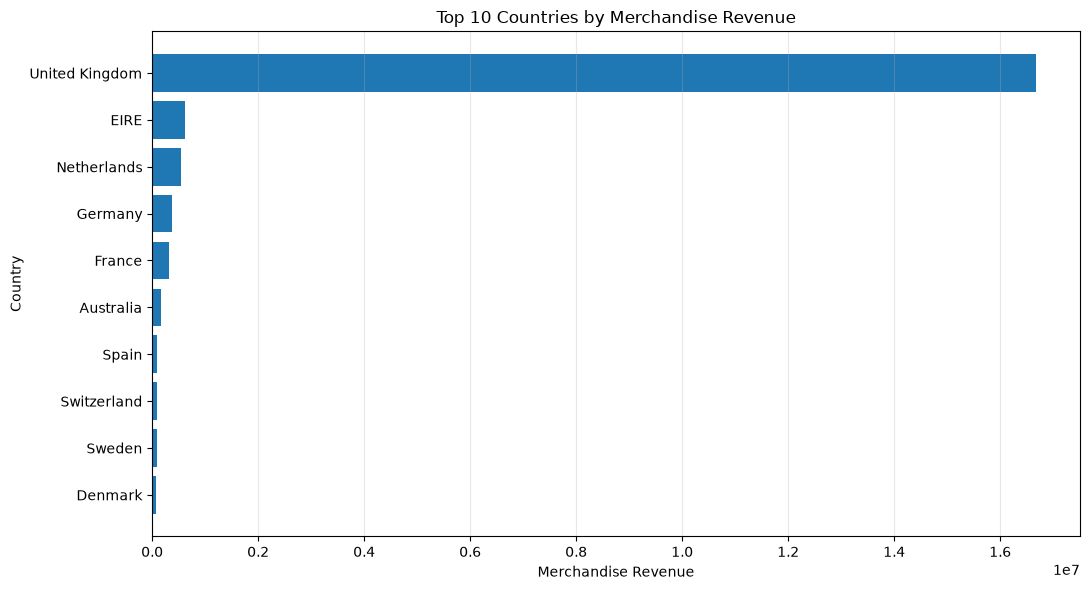

In [37]:
import matplotlib.pyplot as plt

top_countries_merchandise = (
    country_merchandise_sales
    .head(10)
    .sort_values("merchandise_revenue")
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_countries_merchandise["country"],
    top_countries_merchandise["merchandise_revenue"]
)

plt.title("Top 10 Countries by Merchandise Revenue")
plt.xlabel("Merchandise Revenue")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
# Core KPIs for the preliminary merchandise dataset

total_revenue = sales_df["revenue"].sum()
total_units = sales_df["quantity"].sum()
total_invoices = sales_df["invoice"].nunique()
total_products = sales_df["stockcode"].nunique()
total_countries = sales_df["country"].nunique()
total_customers = sales_df["customer_id"].nunique()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Merchandise Revenue",
        "Units Sold",
        "Unique Invoices",
        "Unique Products",
        "Countries",
        "Identified Customers"
    ],
    "Value": [
        round(total_revenue, 2),
        int(total_units),
        int(total_invoices),
        int(total_products),
        int(total_countries),
        int(total_customers)
    ]
})

display(kpi_summary)

,Metric,Value
0,Merchandise Revenue,19499175.72
1,Units Sold,11127534.00
2,Unique Invoices,39553.00
3,Unique Products,4878.00
4,Countries,43.00
5,Identified Customers,5852.00


In [39]:
# Customer purchasing behavior

customer_summary = (
    sales_df.dropna(subset=["customer_id"])
    .groupby("customer_id")
    .agg(
        total_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        invoice_count=("invoice", "nunique"),
        first_purchase=("invoicedate", "min"),
        last_purchase=("invoicedate", "max")
    )
    .reset_index()
)

customer_summary["average_revenue_per_invoice"] = (
    customer_summary["total_revenue"]
    / customer_summary["invoice_count"]
)

customer_summary = customer_summary.sort_values(
    "total_revenue",
    ascending=False
)

print("Identified customers:", len(customer_summary))
print("\nTop 10 customers by merchandise revenue:")

display(
    customer_summary.head(10).style.format({
        "total_revenue": "{:,.2f}",
        "total_quantity": "{:,.0f}",
        "average_revenue_per_invoice": "{:,.2f}"
    })
)

Identified customers: 5852

Top 10 customers by merchandise revenue:


,customer_id,total_revenue,total_quantity,invoice_count,first_purchase,last_purchase,average_revenue_per_invoice
5666,18102,"573,427.32","176,593",145,2009-12-01 09:24:00,2011-12-09 11:50:00,"3,954.67"
2263,14646,"524,718.57","366,447",145,2009-12-02 16:52:00,2011-12-08 12:12:00,"3,618.75"
1779,14156,"300,492.43","162,529",145,2009-12-01 12:30:00,2011-11-30 10:54:00,"2,072.36"
2521,14911,"278,105.45","147,316",376,2009-12-01 11:41:00,2011-12-08 15:54:00,739.64
5026,17450,"234,217.52","81,805",51,2010-09-27 16:59:00,2011-12-01 13:29:00,"4,592.50"
1322,13694,"195,290.05","187,793",143,2009-12-04 15:26:00,2011-12-06 09:32:00,"1,365.66"
5085,17511,"171,140.23","116,670",60,2009-12-02 10:52:00,2011-12-07 10:12:00,"2,852.34"
4038,16446,"168,472.50","80,997",2,2011-05-18 09:52:00,2011-12-09 09:15:00,"84,236.25"
4272,16684,"145,555.17","104,054",55,2009-12-07 12:56:00,2011-12-05 14:06:00,"2,646.46"
67,12415,"141,726.22","90,782",24,2010-06-30 08:30:00,2011-11-15 14:22:00,"5,905.26"


In [40]:
# Classify customers by number of distinct invoices

customer_summary["customer_type"] = customer_summary[
    "invoice_count"
].apply(
    lambda count: "One-time buyer"
    if count == 1
    else "Repeat buyer"
)

customer_type_summary = (
    customer_summary
    .groupby("customer_type")
    .agg(
        customer_count=("customer_id", "count"),
        total_revenue=("total_revenue", "sum"),
        average_revenue=("total_revenue", "mean")
    )
    .reset_index()
)

customer_type_summary["customer_percentage"] = (
    customer_type_summary["customer_count"]
    / len(customer_summary) * 100
)

display(
    customer_type_summary.round({
        "total_revenue": 2,
        "average_revenue": 2,
        "customer_percentage": 2
    })
)

,customer_type,customer_count,total_revenue,average_revenue,customer_percentage
0,One-time buyer,1618,552438.74,341.43,27.65
1,Repeat buyer,4234,16395243.00,3872.28,72.35


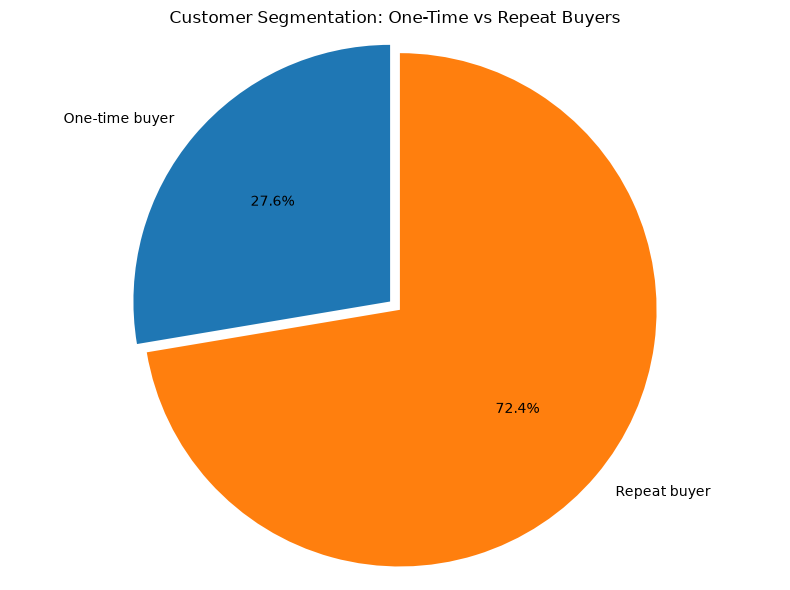

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.pie(
    customer_type_summary["customer_count"],
    labels=customer_type_summary["customer_type"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.05)
)

plt.title("Customer Segmentation: One-Time vs Repeat Buyers")
plt.axis("equal")
plt.tight_layout()
plt.show()

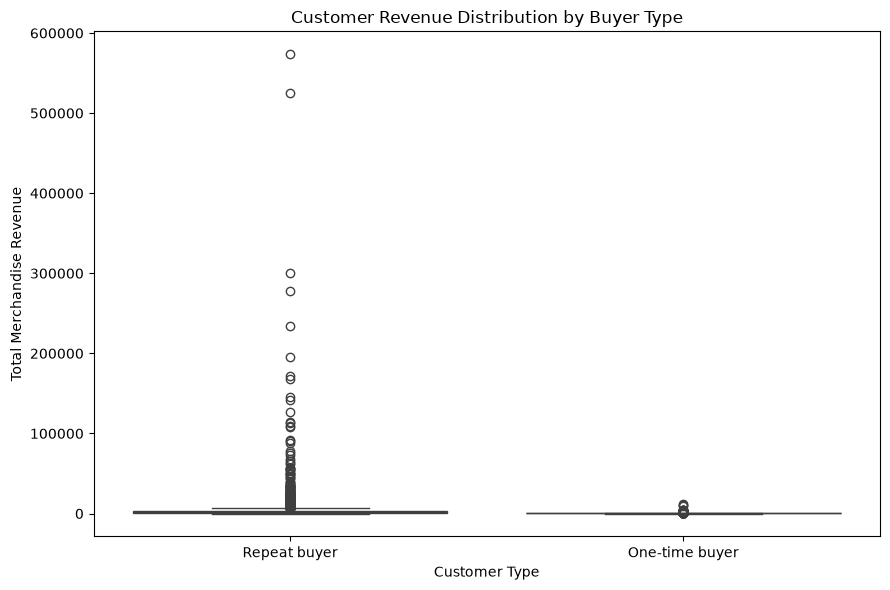

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=customer_summary,
    x="customer_type",
    y="total_revenue"
)

plt.title("Customer Revenue Distribution by Buyer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Merchandise Revenue")
plt.tight_layout()
plt.show()

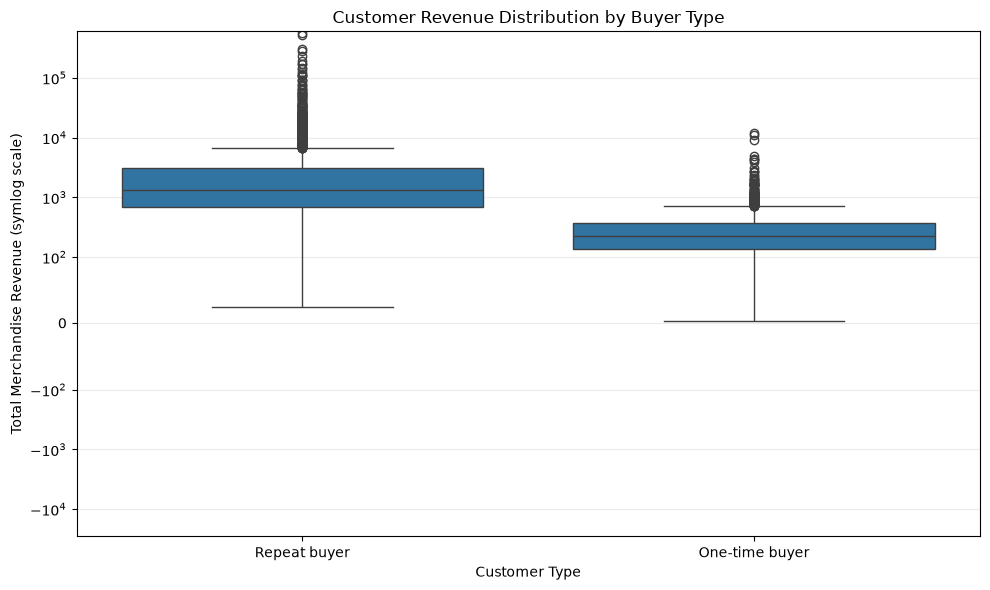

In [43]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=customer_summary,
    x="customer_type",
    y="total_revenue"
)

plt.yscale("symlog", linthresh=100)
plt.title("Customer Revenue Distribution by Buyer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Merchandise Revenue (symlog scale)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

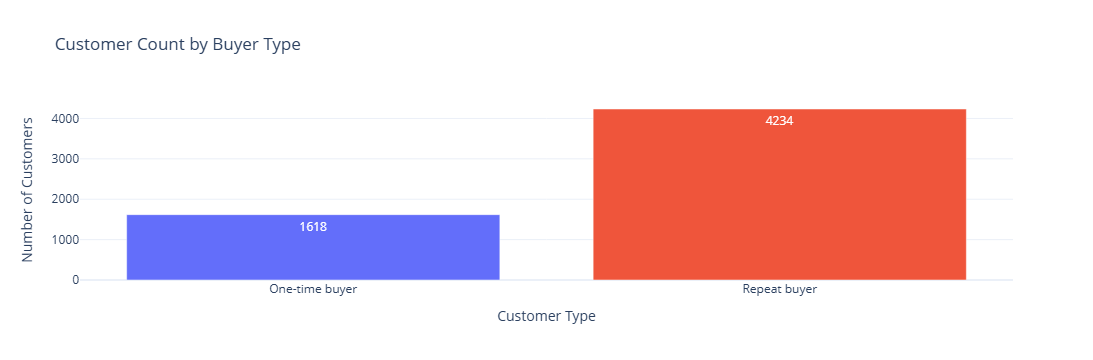

In [44]:
import plotly.express as px

fig = px.bar(
    customer_type_summary,
    x="customer_type",
    y="customer_count",
    color="customer_type",
    text="customer_count",
    title="Customer Count by Buyer Type",
    labels={
        "customer_type": "Customer Type",
        "customer_count": "Number of Customers"
    },
    hover_data={
        "customer_percentage": ":.2f",
        "total_revenue": ":,.2f"
    }
)

fig.update_layout(
    template="plotly_white",
    showlegend=False,
    xaxis_title="Customer Type",
    yaxis_title="Number of Customers"
)

fig.show()

In [45]:
# Save analysis outputs for the dashboard

from pathlib import Path

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

monthly_merchandise_sales.to_csv(
    output_dir / "monthly_sales.csv",
    index=False
)

country_merchandise_sales.to_csv(
    output_dir / "country_sales.csv",
    index=False
)

customer_type_summary.to_csv(
    output_dir / "customer_segmentation.csv",
    index=False
)

customer_summary.to_csv(
    output_dir / "customer_summary.csv",
    index=False
)

kpi_summary.to_csv(
    output_dir / "kpi_summary.csv",
    index=False
)

print("Dashboard summary files saved to:", output_dir)
print("Files created: 5")

Dashboard summary files saved to: C:\Users\idivysh\Downloads\Career Portfolio\Projects\Retail Sales Analytics\retail-sales-analytics\data\processed
Files created: 5


In [47]:
df_clean["price"].describe()

count    1.033036e+06
mean     4.613980e+00
std      1.223975e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: price, dtype: float64

In [48]:
print(df_clean.columns.tolist())

['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country', 'revenue']


In [49]:
print(df_clean[["price", "quantity"]].describe())

              price      quantity
count  1.033036e+06  1.033036e+06
mean   4.613980e+00  1.007688e+01
std    1.223975e+02  1.751976e+02
min   -5.359436e+04 -8.099500e+04
25%    1.250000e+00  1.000000e+00
50%    2.100000e+00  3.000000e+00
75%    4.150000e+00  1.000000e+01
max    3.897000e+04  8.099500e+04


In [50]:
print("Negative prices:", (df_clean["price"] < 0).sum())
print("Zero prices:", (df_clean["price"] == 0).sum())
print("Negative quantities:", (df_clean["quantity"] < 0).sum())
print("Zero quantities:", (df_clean["quantity"] == 0).sum())

print("\nTransactions with negative prices:")
display(
    df_clean.loc[
        df_clean["price"] < 0,
        ["invoice", "description", "quantity", "price", "revenue"]
    ].head(10)
)

Negative prices: 5
Zero prices: 6014
Negative quantities: 22496
Zero quantities: 0

Transactions with negative prices:


,invoice,description,quantity,price,revenue
179403,A506401,Adjust bad debt,1,-53594.36,-53594.36
276274,A516228,Adjust bad debt,1,-44031.79,-44031.79
403472,A528059,Adjust bad debt,1,-38925.87,-38925.87
825444,A563186,Adjust bad debt,1,-11062.06,-11062.06
825445,A563187,Adjust bad debt,1,-11062.06,-11062.06


In [51]:
zero_price_df = df_clean.loc[
    df_clean["price"] == 0,
    ["invoice", "stockcode", "description", "quantity", "price", "revenue"]
]

print("Total zero-price rows:", len(zero_price_df))

print("\nMost common descriptions:")
display(zero_price_df["description"].value_counts().head(15))

print("\nSample zero-price transactions:")
display(zero_price_df.head(15))

Total zero-price rows: 6014

Most common descriptions:


description
check                                  160
?                                       91
damages                                 84
damaged                                 81
found                                   28
missing                                 27
sold as set on dotcom                   20
CHILLI LIGHTS                           17
Damaged                                 17
adjustment                              16
POLYESTER FILLER PAD 45x45cm            15
OWL DOORSTOP                            15
PICNIC BASKET WICKER LARGE              13
60 GOLD AND SILVER FAIRY CAKE CASES     12
dotcom                                  12
Name: count, dtype: int64


Sample zero-price transactions:


,invoice,stockcode,description,quantity,price,revenue
263,489464,21733,85123a mixed,-96,0.0,-0.0
283,489463,71477,short,-240,0.0,-0.0
284,489467,85123A,21733 mixed,-192,0.0,-0.0
470,489521,21646,NaN,-50,0.0,-0.0
3114,489655,20683,RAIN GIRL CHILDS UMBRELLA,-44,0.0,-0.0
3161,489659,21350,GINGHAM HEART WREATH,230,0.0,0.0
3162,489660,35956,lost,-1043,0.0,-0.0
3168,489663,35605A,damages,-117,0.0,-0.0
3731,489781,84292,ROSE PINK METAL FOLDING CHAIR,17,0.0,0.0
4296,489806,18010,ASSORTED FRAGRANCE BATH CONFETTI,-770,0.0,-0.0


In [52]:
print("Negative quantity rows by invoice prefix:")
print(
    df_clean.loc[df_clean["quantity"] < 0, "invoice"]
    .astype(str)
    .str.startswith("C")
    .value_counts()
)

print("\nSample negative-quantity transactions:")
display(
    df_clean.loc[
        df_clean["quantity"] < 0,
        ["invoice", "description", "quantity", "price", "revenue"]
    ].head(10)
)

Negative quantity rows by invoice prefix:
invoice
True     19103
False     3393
Name: count, dtype: int64

Sample negative-quantity transactions:


,invoice,description,quantity,price,revenue
178,C489449,PAPER BUNTING WHITE LACE,-12,2.95,-35.40
179,C489449,CREAM FELT EASTER EGG BASKET,-6,1.65,-9.90
180,C489449,POTTING SHED SOW 'N' GROW SET,-4,4.25,-17.00
181,C489449,POTTING SHED TWINE,-6,2.10,-12.60
182,C489449,PAPER CHAIN KIT RETRO SPOT,-12,2.95,-35.40
183,C489449,SAVE THE PLANET MUG,-12,1.25,-15.00
184,C489449,ANTIQUE SILVER TEA GLASS ETCHED,-12,1.25,-15.00
185,C489449,HANGING HEART ZINC T-LIGHT HOLDER,-24,0.85,-20.40
186,C489449,PAPER BUNTING RETRO SPOTS,-12,2.95,-35.40
196,C489459,PURPLE SWEETHEART BRACELET,-3,4.25,-12.75
